<a href="https://colab.research.google.com/github/Abdoulaye279/Financial-Engineering/blob/main/market-signals/03_pairs.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 03 - Pairs: persistence of cointegration from one year to the next

Seven assets (S&P 500, Apple, Microsoft, JPMorgan, Exxon, gold, Treasuries), 21 pairs, Engle-Granger test on each calendar year 2005-2025 with a critical value simulated for 252 days. If the pairs that pass were real, they should pass again the next year more often than the others. Then the same test on pairs with an economic link: three first (JPMorgan / Bank of America, Coca-Cola / PepsiCo, Exxon / Chevron), then 43 same-industry pairs, with bootstrap nulls, 1 to 3-year windows and the Johansen test. Takes ~4 min.

In [1]:
# colab: get the repo first
try:
    import google.colab
    !git clone -q https://github.com/Abdoulaye279/Financial-Engineering
    %cd Financial-Engineering/market-signals
except ImportError:
    pass

In [2]:
import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats as st
from signals import *
plt.style.use("quant.mplstyle")

names = ["aapl", "msft", "jpm", "xom", "gld", "tlt"]
P = pd.concat({**{n: load_close(f"../var-es-sp500/data/{n}.csv") for n in names},
               "spx": load_close("../black-scholes-sp500/data/sp500.csv")}, axis=1)
L = np.log(P).dropna()
print(L.shape, L.index[0].date(), "->", L.index[-1].date())

(5536, 7) 2004-11-18 -> 2026-11-19


In [3]:
# Engle-Granger critical value for one year of data, simulated with two independent random walks
cv = eg_critical(252, sims=4000)
print(f"5% critical value for 252 days: {cv:.2f}  (the plain Dickey-Fuller value -2.87 would be too lenient)")
# the residual comes from a fitted regression, which already makes it look stationary: the critical value
# has to be lower than Dickey-Fuller's. -3.38 here, MacKinnon gives -3.37

5% critical value for 252 days: -3.38  (the plain Dickey-Fuller value -2.87 would be too lenient)


In [4]:
rows = []
for y in range(2005, 2026):
    for a, b in itertools.combinations(L.columns, 2):
        now, nxt = L.loc[str(y)], L.loc[str(y + 1)]
        if len(nxt) < 200:
            continue
        beta, c, t = engle_granger(now[a].values, now[b].values)
        rows.append({"year": y, "pair": f"{a}/{b}", "beta": beta, "t": t, "t next year": engle_granger(nxt[a].values, nxt[b].values)[2]})
d = pd.DataFrame(rows)
d["pass"], d["pass next year"] = d["t"] < cv, d["t next year"] < cv
k, n = d["pass"].sum(), len(d)
print(f"{n} tests (21 pairs x {d.year.nunique()} years), {k} pass at 5% ({k / n:.1%}), {0.05 * n:.0f} expected by chance")
print(f"binomial test against 5%: p = {st.binomtest(k, n, 0.05).pvalue:.3f}")
# 34 passes for 22 expected: a bit more than chance (p = 0.015), but the 441 tests are not independent
# (each asset is in 6 pairs, the same year shocks every pair), so this p-value is too small

441 tests (21 pairs x 21 years), 34 pass at 5% (7.7%), 22 expected by chance
binomial test against 5%: p = 0.015


In [5]:
# the 441 tests share assets and days, so the binomial p-value assumes too much independence.
# null with the real dependence: resample blocks of 21 days of the joint 7-asset returns (same days for every
# asset, so correlations and vol clustering stay) and rebuild prices: no cointegration by construction (~1 min)
R = L.diff().dropna().values
years = L.index.year[1:]
rng = np.random.default_rng(1)
counts = []
for _ in range(300):
    starts = rng.integers(0, len(R) - 21, len(R) // 21 + 1)
    Rb = np.concatenate([R[i:i + 21] for i in starts])[:len(R)]
    Lb = Rb.cumsum(0)
    k_b = 0
    for y in range(2005, 2026):
        m = years == y
        for i, j in itertools.combinations(range(L.shape[1]), 2):
            k_b += engle_granger(Lb[m, i], Lb[m, j])[2] < cv
    counts.append(k_b)
counts = np.array(counts)
print(f"passes under the bootstrap null: mean {counts.mean():.1f}, sd {counts.std():.1f} (binomial sd {np.sqrt(n * 0.05 * 0.95):.1f}), "
      f"95th percentile {np.percentile(counts, 95):.0f}")
print(f"observed {k}: bootstrap p = {(counts >= k).mean():.2f}")
# with the fat tails, vol clustering, drifts and correlations of the real data, 43 passes (9.8%) are expected with
# no cointegration at all, and the spread is twice the binomial one. the 34 passes are below that: p = 0.82
# the "a bit more than chance" of the binomial test came from assuming independent Gaussian random walks

passes under the bootstrap null: mean 43.0, sd 10.0 (binomial sd 4.6), 95th percentile 60
observed 34: bootstrap p = 0.82


In [6]:
tab = pd.crosstab(d["pass"], d["pass next year"])
print(tab)
print(f"pass next year | passed this year: {tab.loc[True, True] / tab.loc[True].sum():.1%}")
print(f"pass next year | failed this year: {tab.loc[False, True] / tab.loc[False].sum():.1%}")
print(f"Fisher exact test: p = {st.fisher_exact(tab.values)[1]:.2f}")
# the real check: a pair that passed has a 5.9% chance to pass the next year, a pair that failed 7.6%
# passing one year says nothing about the next (p = 1.00). what the test found was noise

pass next year  False  True 
pass                        
False             376     31
True               32      2
pass next year | passed this year: 5.9%
pass next year | failed this year: 7.6%
Fisher exact test: p = 1.00


In [7]:
# pairs with an economic reason: two banks, two soda makers, two oil majors, 2000-2025
L2 = np.log(pd.concat({n: load_close(f"data/{n}.csv") for n in ["bac", "ko", "pep", "cvx"]} |
                      {n: load_close(f"../var-es-sp500/data/{n}.csv") for n in ["jpm", "xom"]}, axis=1)).dropna()
rows = []
for a, b in [("jpm", "bac"), ("ko", "pep"), ("xom", "cvx")]:
    for y in range(2000, 2026):
        now, nxt = L2.loc[str(y)], L2.loc[str(y + 1)]
        rows.append({"year": y, "pair": f"{a}/{b}", "t": engle_granger(now[a].values, now[b].values)[2],
                     "t next year": engle_granger(nxt[a].values, nxt[b].values)[2]})
d2 = pd.DataFrame(rows)
d2["pass"], d2["pass next year"] = d2["t"] < cv, d2["t next year"] < cv
k2 = d2["pass"].sum()
print(f"{len(d2)} tests, {k2} pass ({k2 / len(d2):.1%}), binomial p against 5% = {st.binomtest(k2, len(d2), 0.05).pvalue:.2f}")
print(d2.groupby("pair")["pass"].sum().to_dict())
tab2 = pd.crosstab(d2["pass"], d2["pass next year"])
print(tab2)
print(f"pass next year | passed: {tab2.loc[True, True] / tab2.loc[True].sum():.0%}, | failed: {tab2.loc[False, True] / tab2.loc[False].sum():.0%}, "
      f"Fisher p = {st.fisher_exact(tab2.values)[1]:.2f}")
cv_all = eg_critical(len(L2), sims=500)
print(f"whole 2000-2026 ({len(L2)} days, 5% critical value {cv_all:.2f}):",
      {f"{a}/{b}": round(engle_granger(L2[a].values, L2[b].values)[2], 2) for a, b in [("jpm", "bac"), ("ko", "pep"), ("xom", "cvx")]})
# same-industry pairs pass a bit more often (10.3% vs 7.7%) and a pass is followed by another pass 25% of the
# time vs 10% after a fail. that is the direction a real link would give, but 8 passes is too few: Fisher p = 0.23
# over the whole 26 years none of the three is cointegrated (t from -0.31 to -2.42, critical -3.33):
# the link holds for a year or two, then the prices drift apart

78 tests, 8 pass (10.3%), binomial p against 5% = 0.06
{'jpm/bac': 3, 'ko/pep': 3, 'xom/cvx': 2}
pass next year  False  True 
pass                        
False              63      7
True                6      2
pass next year | passed: 25%, | failed: 10%, Fisher p = 0.23


whole 2000-2026 (6763 days, 5% critical value -3.33): {'jpm/bac': np.float64(-0.31), 'ko/pep': np.float64(-2.42), 'xom/cvx': np.float64(-2.16)}


In [8]:
# how many tests would be needed? simulate the 2x2 table with pass rate 10% and persistence 25% vs 10%
rng = np.random.default_rng(2)
for n_tests in [78, 300, 1000, 2000]:
    rej = 0
    for _ in range(1000):
        p_now = rng.random(n_tests) < 0.10
        p_next = rng.random(n_tests) < np.where(p_now, 0.25, 0.10)
        tb = [[(p_now & p_next).sum(), (p_now & ~p_next).sum()], [(~p_now & p_next).sum(), (~p_now & ~p_next).sum()]]
        rej += st.fisher_exact(tb)[1] < 0.05
    print(f"{n_tests:5d} tests: power {rej / 1000:.0%}")
# with 78 tests a true 25% vs 10% persistence would be detected only 18% of the time: the Fisher p of 0.23 above says little
# about 1,000 tests (about 40 same-industry pairs over 25 years) would be needed for 97% power
# and the bootstrap above says 10% passes is what no cointegration already gives: the pass rate itself is no evidence

   78 tests: power 18%


  300 tests: power 58%


 1000 tests: power 97%


 2000 tests: power 100%


In [9]:
# 43 same-industry pairs (40 more from data/pairs_close.csv, adjusted closes from Yahoo Finance), 2000-2025
px = pd.read_csv("data/pairs_close.csv", index_col=0, parse_dates=True)
LP = np.log(pd.concat([px] + [load_close(f"data/{n}.csv").rename(n.upper()) for n in ["bac", "ko", "pep", "cvx"]]
                      + [load_close(f"../var-es-sp500/data/{n}.csv").rename(n.upper()) for n in ["jpm", "xom"]], axis=1, sort=True))
pairs = [p.split("/") for p in ["WFC/C", "USB/PNC", "GS/MS", "AXP/COF", "JPM/BAC", "MET/PRU", "TRV/ALL", "UNH/ELV", "MCK/CAH",
         "XOM/CVX", "COP/OXY", "SLB/HAL", "KO/PEP", "PG/CL", "KMB/CLX", "GIS/CPB", "HSY/MDLZ", "HD/LOW", "WMT/TGT",
         "MCD/YUM", "PFE/MRK", "JNJ/ABT", "LLY/BMY", "AMGN/GILD", "MSFT/ORCL", "INTC/AMD", "TXN/ADI", "IBM/HPQ",
         "T/VZ", "DIS/CMCSA", "DUK/SO", "AEP/ED", "XEL/WEC", "UPS/FDX", "CAT/DE", "HON/MMM", "LMT/NOC", "GD/RTX",
         "UNP/NSC", "V/MA", "F/GM", "LEN/DHI", "NUE/STLD"]]

def yearly_tests(la, lb, years):
    # Engle-Granger t this year and next year, for every year with 200+ days in both
    out = []
    for y in range(2000, 2026):
        m, m1 = years == y, years == y + 1
        if m.sum() >= 200 and m1.sum() >= 200:
            out.append((y, engle_granger(la[m], lb[m])[2], engle_granger(la[m1], lb[m1])[2]))
    return out

rows = []
for a, b in pairs:
    x2 = LP[[a, b]].dropna()
    rows += [{"pair": f"{a}/{b}", "year": y, "t": t, "t next year": tn}
             for y, t, tn in yearly_tests(x2[a].values, x2[b].values, x2.index.year)]
d3 = pd.DataFrame(rows)
d3["pass"], d3["pass next year"] = d3["t"] < cv, d3["t next year"] < cv
tab3 = pd.crosstab(d3["pass"], d3["pass next year"])
print(f"{len(pairs)} pairs, {len(d3)} tests, {d3['pass'].mean():.1%} pass")
print(tab3)
pp = tab3.loc[True, True] / tab3.loc[True].sum()
lo, hi = st.binomtest(tab3.loc[True, True], tab3.loc[True].sum()).proportion_ci()
print(f"pass next year | passed: {pp:.1%} (95% CI {lo:.0%}-{hi:.0%}), | failed: {tab3.loc[False, True] / tab3.loc[False].sum():.1%}, "
      f"Fisher p = {st.fisher_exact(tab3.values)[1]:.2f}")
print("most passes:", d3.groupby("pair")["pass"].sum().sort_values(ascending=False).head(6).to_dict())
# 1,093 tests, the 97% power asked for above. after a pass 12.6% pass again, after a fail 9.3%: Fisher p = 0.24
# the 95% interval 7%-20% excludes the 25% persistence tested above: a link that lasts is rare at best
# no pair stands out: the best, V/MA and NUE/STLD, pass 6 years out of 18 and 26

43 pairs, 1093 tests, 10.2% pass
pass next year  False  True 
pass                        
False             891     91
True               97     14
pass next year | passed: 12.6% (95% CI 7%-20%), | failed: 9.3%, Fisher p = 0.24
most passes: {'V/MA': 6, 'NUE/STLD': 6, 'AEP/ED': 5, 'LEN/DHI': 5, 'MET/PRU': 5, 'UPS/FDX': 5}


In [10]:
# pass rate with no cointegration for these pairs: block bootstrap of each pair's joint returns (~1 min)
rng = np.random.default_rng(3)
null = []
for _ in range(100):
    k_b = n_b = 0
    for a, b in pairs:
        x2 = LP[[a, b]].dropna()
        R2 = np.diff(x2.values, axis=0)
        st_ = rng.integers(0, len(R2) - 21, len(R2) // 21 + 1)
        Lb = np.concatenate([R2[i:i + 21] for i in st_])[:len(R2)].cumsum(0)
        res = yearly_tests(Lb[:, 0], Lb[:, 1], x2.index.year[1:])
        k_b += sum(t < cv for _, t, _ in res); n_b += len(res)
    null.append(k_b / n_b)
null = np.array(null)
print(f"pass rate with no cointegration: {null.mean():.1%} (sd {null.std():.1%}); observed {d3['pass'].mean():.1%}, "
      f"bootstrap p = {(null >= d3['pass'].mean()).mean():.2f}")
# with no cointegration at all these pairs would pass 11.8% of the time; they pass 10.2%
# same-industry pairs are not more cointegrated, year by year, than unrelated random walks with the same returns

pass rate with no cointegration: 11.8% (sd 0.9%); observed 10.2%, bootstrap p = 0.97


In [11]:
# longer blocks keep slower changes in volatility: 63 days (a quarter) and 252 days (a year), 50 histories each (~1 min)
for block in [63, 252]:
    rng = np.random.default_rng(4)
    nl = []
    for _ in range(50):
        k_b = n_b = 0
        for a, b in pairs:
            x2 = LP[[a, b]].dropna()
            R2 = np.diff(x2.values, axis=0)
            st_ = rng.integers(0, len(R2) - block, len(R2) // block + 1)
            Lb = np.concatenate([R2[i:i + block] for i in st_])[:len(R2)].cumsum(0)
            res = yearly_tests(Lb[:, 0], Lb[:, 1], x2.index.year[1:])
            k_b += sum(t < cv for _, t, _ in res); n_b += len(res)
        nl.append(k_b / n_b)
    print(f"blocks of {block:3d} days: pass rate with no cointegration {np.mean(nl):.1%} (sd {np.std(nl):.1%}), observed {d3['pass'].mean():.1%}")
# 11.8% with 21 or 63-day blocks, 10.6% with one-year blocks that keep each year's volatility level
# the observed 10.2% is below all three: the conclusion does not depend on the block length

blocks of  63 days: pass rate with no cointegration 11.8% (sd 0.8%), observed 10.2%


blocks of 252 days: pass rate with no cointegration 10.6% (sd 0.9%), observed 10.2%


In [12]:
# longer windows and a second test: Engle-Granger and Johansen on 1, 2 and 3-year windows, each window against the
# next one. critical values simulated for each window length (~1 min)
rows = []
for w in [1, 2, 3]:
    n_days = 252 * w
    cv_eg, cv_jo = critical_value(lambda Y: engle_granger(Y[:, 0], Y[:, 1])[2], n_days), critical_value(johansen_trace, n_days, upper=True)
    for a, b in pairs:
        x2 = LP[[a, b]].dropna()
        blk = (x2.index.year - 2000) // w
        res = []
        for g in range(blk.max()):
            m, m1 = blk == g, blk == g + 1
            if m.sum() >= 200 * w and m1.sum() >= 200 * w:
                res.append([(engle_granger(x2.values[mm, 0], x2.values[mm, 1])[2] < cv_eg, johansen_trace(x2.values[mm]) > cv_jo) for mm in (m, m1)])
        for (eg0, jo0), (eg1, jo1) in res:
            rows.append({"window": w, "pair": f"{a}/{b}", "EG": eg0, "EG next": eg1, "Johansen": jo0, "Johansen next": jo1})
dw = pd.DataFrame(rows)
out = {}
for (w, test), g in [((w, t), dw[dw.window == w]) for w in [1, 2, 3] for t in ["EG", "Johansen"]]:
    tb = pd.crosstab(g[test], g[test + " next"]).reindex(index=[False, True], columns=[False, True], fill_value=0)
    out[(f"{w} year" + "s" * (w > 1), test)] = {"windows tested": len(g), "pass": g[test].mean(),
        "next | pass": tb.loc[True, True] / max(tb.loc[True].sum(), 1), "next | fail": tb.loc[False, True] / tb.loc[False].sum(),
        "Fisher p": st.fisher_exact(tb.values)[1]}
pd.DataFrame(out).T.style.format({"windows tested": "{:.0f}", "pass": "{:.1%}", "next | pass": "{:.1%}", "next | fail": "{:.1%}", "Fisher p": "{:.2f}"})
# longer windows pass more often (EG 10.7%, 16.9%, 21.6% for 1, 2, 3 years) but the critical values come from Gaussian
# random walks, and the bootstrap above showed that real returns already pass about twice the nominal 5%
# persistence is never significant (Fisher p 0.20 to 0.75, both tests, every window). with Engle-Granger on 2 and 3 years
# a pass is even followed by a pass less often than a fail (15.3% vs 17.5%, 16.7% vs 19.8%); only Johansen on 3 years
# leans the other way (22.2% vs 15.5%, p = 0.20)
# (the 1-year EG rate is 10.7% here, not 10.2%: critical value from 2,000 simulations instead of 4,000)

In [13]:
# stricter null for longer windows: block bootstrap (63 days) of each pair's returns, same windows and critical
# values as above, 30 histories (~2 min)
rng = np.random.default_rng(5)
cvs = {w: (critical_value(lambda Y: engle_granger(Y[:, 0], Y[:, 1])[2], 252 * w), critical_value(johansen_trace, 252 * w, upper=True)) for w in [1, 2, 3]}
sim = {(w, t): [] for w in [1, 2, 3] for t in ["EG", "Johansen"]}
for _ in range(30):
    cnt = {key: [0, 0] for key in sim}
    for a, b in pairs:
        x2 = LP[[a, b]].dropna()
        R2 = np.diff(x2.values, axis=0)
        st_ = rng.integers(0, len(R2) - 63, len(R2) // 63 + 1)
        Lb = np.concatenate([R2[i:i + 63] for i in st_])[:len(R2)].cumsum(0)
        yrs = x2.index.year[1:]
        for w in [1, 2, 3]:
            blk = (yrs - 2000) // w
            for g in range(blk.max() + 1):
                m = blk == g
                if m.sum() >= 200 * w:
                    cnt[(w, "EG")][0] += engle_granger(Lb[m, 0], Lb[m, 1])[2] < cvs[w][0]
                    cnt[(w, "Johansen")][0] += johansen_trace(Lb[m]) > cvs[w][1]
                    cnt[(w, "EG")][1] += 1; cnt[(w, "Johansen")][1] += 1
    for key, (k_, n_) in cnt.items():
        sim[key].append(k_ / n_)
for (w, t), v in sim.items():
    obs = dw[dw.window == w][t].mean()
    print(f"{w} year{'s' * (w > 1)} {t:9s} no-cointegration pass rate {np.mean(v):.1%} (sd {np.std(v):.1%}), observed {obs:.1%}, "
          f"bootstrap p = {(np.array(v) >= obs).mean():.2f}")
# 1 year: below what no cointegration gives (10.7% vs 12.7%). 2 years: slightly above, not significant (p 0.17, 0.30)
# 3 years: above with both tests, EG 21.6% vs 16.9%, Johansen 18.9% vs 14.3%, and none of the 30 histories gets there
# (p < 0.04): over three years same-industry pairs do share a trend more often than chance
# but the persistence table above says a 3-year link does not predict the next 3 years: real, not tradable

1 year EG        no-cointegration pass rate 12.7% (sd 0.8%), observed 10.7%, bootstrap p = 0.97
1 year Johansen  no-cointegration pass rate 13.4% (sd 1.1%), observed 11.0%, bootstrap p = 0.93
2 years EG        no-cointegration pass rate 15.7% (sd 1.4%), observed 16.9%, bootstrap p = 0.17
2 years Johansen  no-cointegration pass rate 15.4% (sd 1.2%), observed 16.1%, bootstrap p = 0.30
3 years EG        no-cointegration pass rate 16.9% (sd 1.9%), observed 21.6%, bootstrap p = 0.00
3 years Johansen  no-cointegration pass rate 14.3% (sd 1.9%), observed 18.9%, bootstrap p = 0.00


In [14]:
d.sort_values("t").head(10).round(2)
# the strongest "pairs" make no economic sense: Microsoft against gold with a negative hedge ratio, Microsoft
# against Treasuries. only xom/gld 2008 passes again in 2009

,year,pair,beta,t,t next year,pass,pass next year
281,2018,msft/gld,-1.76,-5.68,-2.20,True,False
366,2022,msft/tlt,0.74,-5.14,-1.54,True,False
78,2008,xom/gld,0.66,-4.79,-3.48,True,True
378,2023,aapl/msft,0.74,-4.40,-0.91,True,False
139,2011,jpm/tlt,-1.18,-4.38,-1.58,True,False
85,2009,aapl/jpm,1.08,-4.30,-0.90,True,False
89,2009,aapl/spx,2.15,-4.28,-1.48,True,False
323,2020,msft/gld,1.40,-4.04,-0.67,True,False
434,2025,jpm/spx,1.37,-4.01,-2.43,True,False
3,2005,aapl/gld,3.53,-4.00,-1.08,True,False


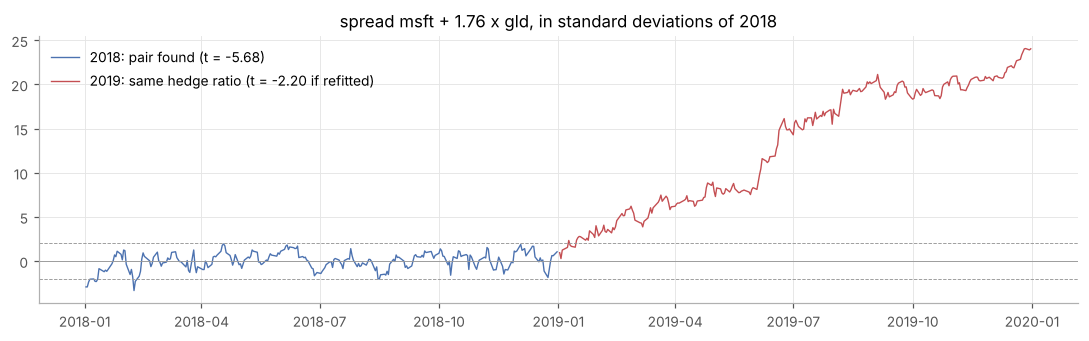

spread at the end of 2019: +24.0 sd


In [15]:
# the strongest pair found: its spread in the year it was found and the year after, same beta and intercept
best = d.sort_values("t").iloc[0]
a, b = best.pair.split("/")
y = best.year
w = L.loc[str(y):str(y + 1)]
beta, c, _ = engle_granger(L.loc[str(y), a].values, L.loc[str(y), b].values)
e = w[a] - beta * w[b] - c
z = (e - e.loc[str(y)].mean()) / e.loc[str(y)].std()
fig, ax = plt.subplots(figsize=(10, 3.2))
ax.plot(z.loc[str(y)], lw=0.9, label=f"{y}: pair found (t = {best.t:.2f})")
ax.plot(z.loc[str(y + 1)], lw=0.9, color="#c44e52", label=f"{y + 1}: same hedge ratio (t = {best['t next year']:.2f} if refitted)")
for lv in (-2, 0, 2):
    ax.axhline(lv, color="#999999", lw=0.6, ls="--" if lv else "-")
ax.set_title(f"spread {a} {'-' if beta > 0 else '+'} {abs(beta):.2f} x {b}, in standard deviations of {y}"); ax.legend(loc="upper left")
plt.tight_layout(); plt.show()
print(f"spread at the end of {y + 1}: {z.iloc[-1]:+.1f} sd")
# msft/gld 2018: t = -5.68, the best of the 441 tests. in 2019 the spread leaves the +-2 sd band early in 2019
# and ends at +24 sd: a trade that bets on the gap closing keeps losing